In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('sample_data/california_housing_train.csv')

In [7]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [8]:
print("Rows and columns:",df.shape)

Rows and columns: (17000, 9)


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


In [10]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000,17000.000000
mean,-119.562108,35.625225,28.589353,2643.664412,539.410824,1429.573941,501.221941,3.883578,207300.912353
std,2.005166,2.137340,12.586937,2179.947071,421.499452,1147.852959,384.520841,1.908157,115983.764387
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.790000,33.930000,18.000000,1462.000000,297.000000,790.000000,282.000000,2.566375,119400.000000
50%,-118.490000,34.250000,29.000000,2127.000000,434.000000,1167.000000,409.000000,3.544600,180400.000000
75%,-118.000000,37.720000,37.000000,3151.250000,648.250000,1721.000000,605.250000,4.767000,265000.000000
max,-114.310000,41.950000,52.000000,37937.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [11]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


In [14]:
df = df.drop(['total_rooms', 'population'], axis=1)

In [15]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_bedrooms,0
households,0
median_income,0
median_house_value,0


In [18]:
df.drop([
    'name',
    'email',
    'phone-number',
    'credit_card',
    'reservation_status',
    'reservation_status_date'
], axis=1, inplace=True, errors='ignore')

In [20]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_bedrooms      17000 non-null  float64
 4   households          17000 non-null  float64
 5   median_income       17000 non-null  float64
 6   median_house_value  17000 non-null  float64
dtypes: float64(7)
memory usage: 929.8 KB


In [22]:
# Let's inspect the actual columns in df:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_bedrooms      17000 non-null  float64
 4   households          17000 non-null  float64
 5   median_income       17000 non-null  float64
 6   median_house_value  17000 non-null  float64
dtypes: float64(7)
memory usage: 929.8 KB


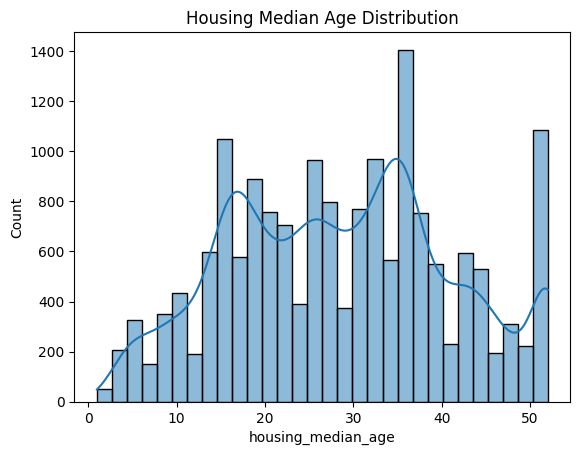

In [25]:
sns.histplot(x='housing_median_age', data=df, bins=30, kde=True)
plt.title("Housing Median Age Distribution")
plt.show()

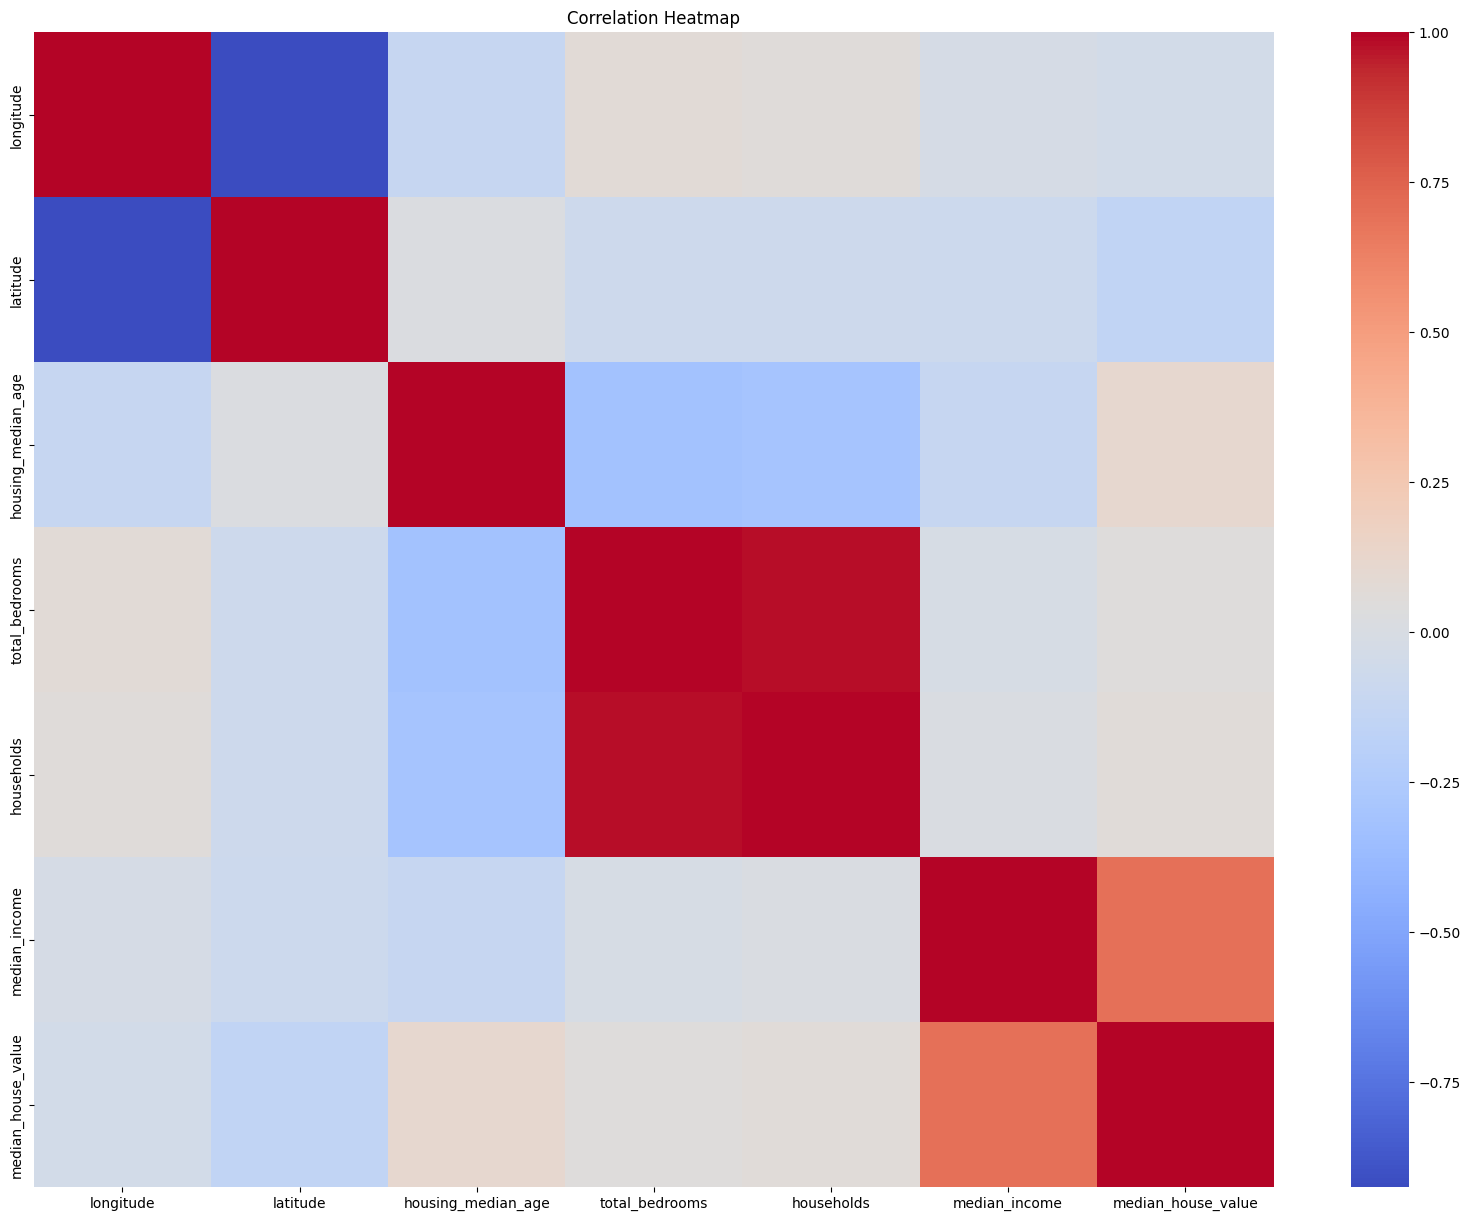

In [26]:
plt.figure(figsize=(20,15))
sns.heatmap(
    df.corr(),
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()

In [28]:
# Dynamically identify categorical columns in the dataset
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if categorical_cols:
    df = pd.get_dummies(
        df,
        columns=categorical_cols,
        drop_first=True
    )
    print(f"Encoded categorical columns: {categorical_cols}")
else:
    print("No categorical columns found to encode. The dataset contains only numeric columns.")

No categorical columns found to encode. The dataset contains only numeric columns.


In [29]:
df

,longitude,latitude,housing_median_age,total_bedrooms,households,median_income,median_house_value
0,-114.31,34.19,15.0,1283.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,1901.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,174.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,337.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,326.0,262.0,1.9250,65500.0
...,...,...,...,...,...,...,...
16995,-124.26,40.58,52.0,394.0,369.0,2.3571,111400.0
16996,-124.27,40.69,36.0,528.0,465.0,2.5179,79000.0
16997,-124.30,41.84,17.0,531.0,456.0,3.0313,103600.0
16998,-124.30,41.80,19.0,552.0,478.0,1.9797,85800.0


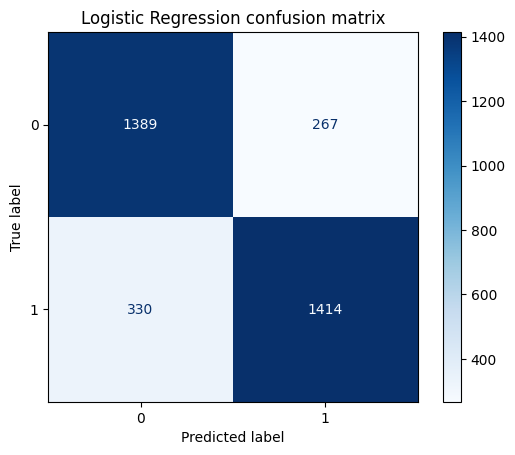

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Prepare features (X) and create a binary target (y) for classification
# e.g., predicting if median_house_value is above the median price
X = df.drop(columns=['median_house_value'])
y = (df['median_house_value'] > df['median_house_value'].median()).astype(int)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Generate predictions
lr_pred = model.predict(X_test)

# Plot the confusion matrix
cm_lr = confusion_matrix(y_test, lr_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm_lr
).plot(cmap='Blues')
plt.title("Logistic Regression confusion matrix")
plt.show()

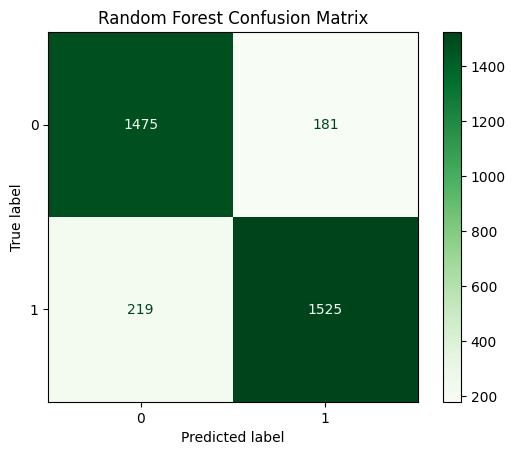

In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Instantiate and train the Random Forest Classifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Generate predictions on the test set
rf_pred = rf_model.predict(X_test)

# Compute and plot the confusion matrix
cm_rf = confusion_matrix(y_test, rf_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf
).plot(cmap='Greens')
plt.title("Random Forest Confusion Matrix")
plt.show()

In [34]:
plt.figure(figsize=(8,6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

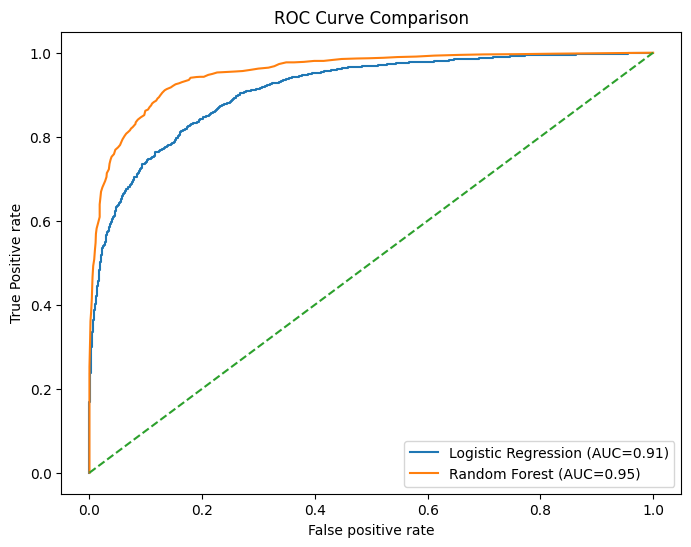

In [36]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get predicted probabilities for the positive class
lr_probs = model.predict_proba(X_test)[:, 1]
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# Calculate False Positive Rate, True Positive Rate, and AUC
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
lr_auc = roc_auc_score(y_test, lr_probs)

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
rf_auc = roc_auc_score(y_test, rf_probs)

# Plot the ROC Curves
plt.figure(figsize=(8,6))
plt.plot(
    lr_fpr,
    lr_tpr,
    label=f'Logistic Regression (AUC={lr_auc:.2f})'
)
plt.plot(
    rf_fpr,
    rf_tpr,
    label=f'Random Forest (AUC={rf_auc:.2f})'
)
plt.plot([0,1],[0,1],'--')
plt.xlabel('False positive rate')
plt.ylabel('True Positive rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

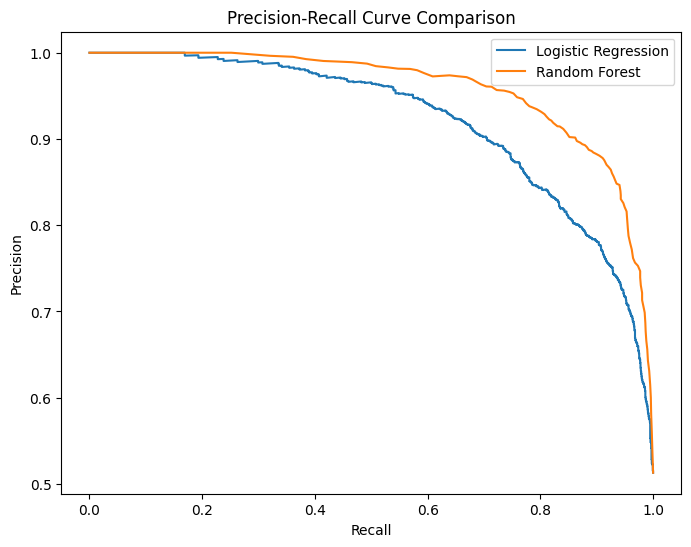

In [38]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Calculate Precision-Recall for Logistic Regression
precision_lr, recall_lr, _ = precision_recall_curve(y_test, lr_probs)

# Calculate Precision-Recall for Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(y_test, rf_probs)

# Plot the Precision-Recall curves
plt.figure(figsize=(8,6))
plt.plot(
    recall_lr,
    precision_lr,
    label='Logistic Regression'
)
plt.plot(
    recall_rf,
    precision_rf,
    label='Random Forest'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.show()

In [40]:
#Extract Feature Importance from Random Forest
importance=pd.DataFrame({
    'Feature':X.columns,
    'Importance':rf_model.feature_importances_
})
importance = importance.sort_values(by='Importance', ascending=False)
importance

,Feature,Importance
5,median_income,0.356590
0,longitude,0.214375
1,latitude,0.209240
3,total_bedrooms,0.073445
4,households,0.073328
2,housing_median_age,0.073024


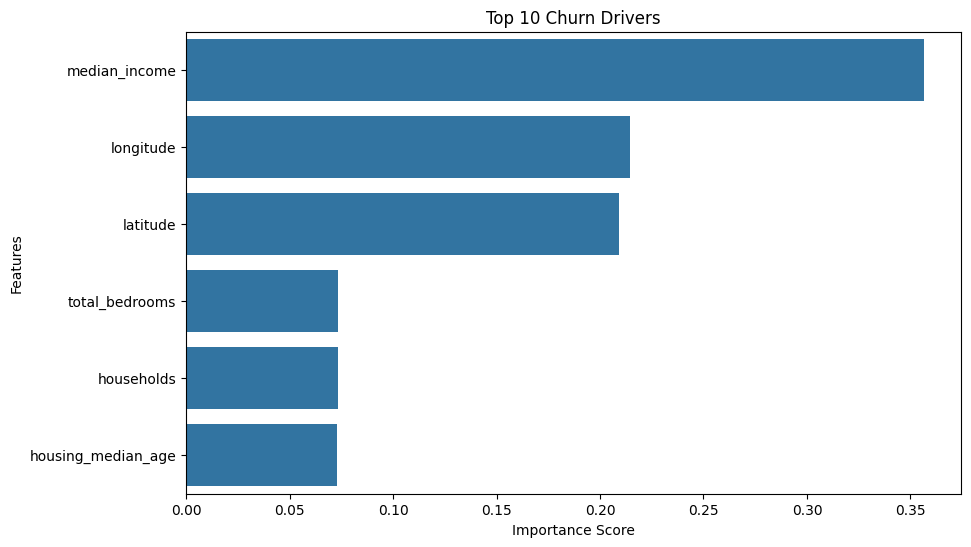

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
top10=importance.head(10)
plt.figure(figsize=(10,6))
sns.barplot(
    data=top10,
    x='Importance',
    y='Feature'
)
plt.title('Top 10 Churn Drivers')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()